Question 10:  Instance Segmentation with Mask R-CNN: Use Detectron2 or Torchvision’s Mask R-CNN to perform instance-level segmentation on the COCO or custom dataset. 

Detected 5 confident real-world object(s):
- person: 1.00 at [222, 414, 351, 861]
- person: 1.00 at [38, 405, 241, 908]
- person: 1.00 at [670, 388, 804, 877]
- bus: 1.00 at [22, 229, 793, 791]
- person: 0.98 at [1, 550, 66, 869]


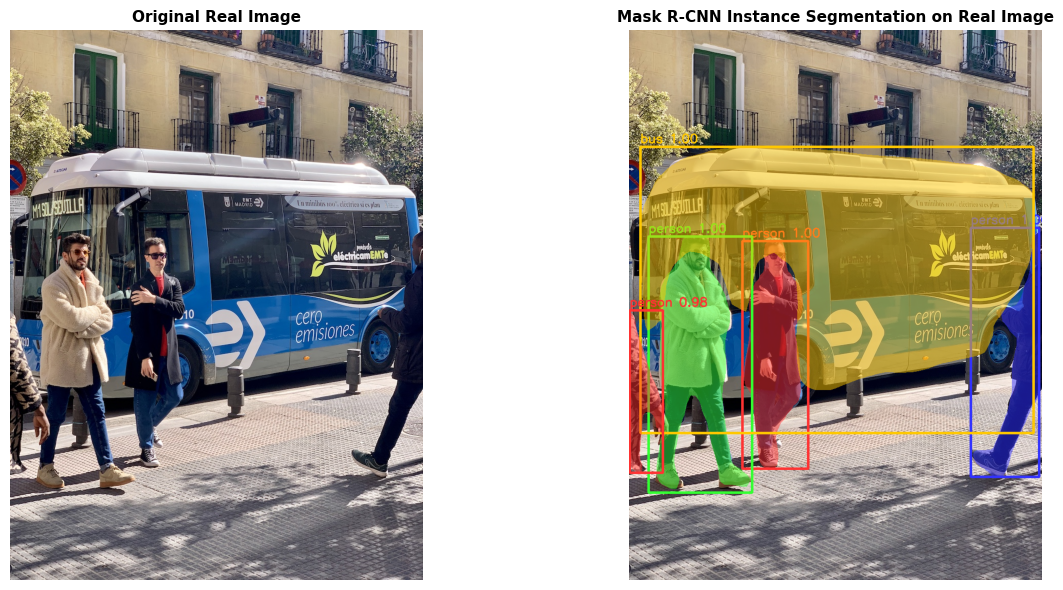

In [2]:
import os
import urllib.request
import torch
import torchvision
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
#img_url = "https://raw.githubusercontent.com/ultralytics/yolov5/master/data/images/bus.jpg"
img_file = "real_scene.jpg"
if not os.path.exists(img_file):
    urllib.request.urlretrieve(img_url, img_file)
pil_img = Image.open(img_file).convert("RGB")
img_np = np.array(pil_img)
weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
model = maskrcnn_resnet50_fpn(weights=weights)
model.eval()
transform = weights.transforms()
img_tensor = transform(pil_img)
with torch.no_grad():
    predictions = model([img_tensor])[0]
scores = predictions['scores'].cpu().numpy()
boxes = predictions['boxes'].cpu().numpy()
labels = predictions['labels'].cpu().numpy()
masks = predictions['masks'].cpu().numpy()
categories = weights.meta["categories"]
CONF_THRESH = 0.7
keep = np.where(scores >= CONF_THRESH)[0]
print(f"Detected {len(keep)} confident real-world object(s):")
orig_w, orig_h = pil_img.size
tensor_h, tensor_w = img_tensor.shape[1], img_tensor.shape[2]
scale_x = orig_w / tensor_w
scale_y = orig_h / tensor_h
output_img = img_np.copy()
colors = [(255, 50, 50), (50, 255, 50), (50, 50, 255), (255, 200, 0)]
for idx in keep:
    label_name = categories[labels[idx]]
    score = scores[idx]
    box = boxes[idx] * np.array([scale_x, scale_y, scale_x, scale_y])
    box = box.astype(np.int32)
    print(f"- {label_name}: {score:.2f} at {box.tolist()}")
    mask = masks[idx, 0]
    mask_resized = cv2.resize((mask > 0.5).astype(np.uint8), (orig_w, orig_h)) > 0
    color = colors[idx % len(colors)]
    output_img[mask_resized] = (0.5 * output_img[mask_resized] + 0.5 * np.array(color)).astype(np.uint8)
    cv2.rectangle(output_img, (box[0], box[1]), (box[2], box[3]), color, 3)
    cv2.putText(output_img, f"{label_name} {score:.2f}", (box[0], max(25, box[1] - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(img_np)
axes[0].set_title("Original Real Image", fontsize=11, fontweight='bold')
axes[0].axis('off')
axes[1].imshow(output_img)
axes[1].set_title("Mask R-CNN Instance Segmentation on Real Image", fontsize=11, fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()